# Nastoyka — этап 3: проверка предварительного авторского меню

**Автор выбрал состав. Расчёт сохраняет все десять позиций без замен:** 8 основных по 250 ₽ и 2 премиальные по 300 ₽ за 50 мл. Единственный источник состава и цен — `data/economics/author_selected_menu.csv`; статус `author_selected_preliminary`. Технологические карты, выходы и безопасное хранение ещё не утверждены.

Далее: история данных → авторский выбор → рецептурные ориентиры → общая закупка → экономика и цены → сравнение с B2 → проверки перед запуском. Подробные ячейки этапа 2 сохранены в конце; новые алгоритмы отбора не запускаются. [Отчёт](docs/economics_report.md) · [Методика](docs/economics_methodology.md).

In [1]:
from pathlib import Path
import json
import pandas as pd
from IPython.display import display, Image, Markdown
from scripts import author_menu as a
from scripts import economics as e
ROOT = Path.cwd()
assert (ROOT / "data/economics/author_selected_menu.csv").exists()
author_result = a.run()
out = ROOT / "data/economics/results"
def ar(name): return pd.read_csv(out / ("author_" + name + ".csv"))
author_menu = a.load_author_menu()
author_items = ar("items")
author_procurement = ar("procurement")
author_comparison = ar("comparison")
author_prices = ar("price_scenarios")
print("Оптимизатор вызван:", author_result["optimizer_called"])
print("Сохранённый авторский набор:", ", ".join(author_result["selected_ids"]))
print("Защищённых первичных файлов:", len(e.check_baseline()["protected_files_sha256"]))

Оптимизатор вызван: False
Сохранённый авторский набор: C01, C02, C03, C04, C05, C09, C13, C14, C06, C12
Защищённых первичных файлов: 14


## 1. История: отзывы, кандидаты, варианты и решение автора

Существующая база: 368 отзывов, 358 подтверждённых публикаций, 468 строк упоминаний, 198 подтверждённых конкретных упоминаний и 114 нормализованных вкусов. Для 275 публикаций доступен видимый фрагмент. Отзывы не равны людям, продажам или репрезентативному опросу.

На базе 15 кандидатов появились A/B/C, затем B2 с усиленной классикой. Автор самостоятельно выбрал иной состав: вернул малину, сохранил малину со сливками, добавил клюкву, исключил из B2 клубнику с базиликом и томатную. Это прямая фиксация решения, не новая оптимизация. Исторические результаты защищены снимком второго этапа; нормализация и исходная книга неизменны.

In [2]:
history = json.loads((ROOT / "data/economics/stage2_baseline.json").read_text())
display(pd.DataFrame([{ "menu": name, "selected": "|".join(value["selected"]), "first_cash_rub": value["purchase_cash_rub"] } for name, value in history["summary"]["menus"].items()]))
print("Предыдущий коммит:", history["commit"])
print("Исторические данные не перезаписываются. Текущий состав ниже:")
display(author_menu)

,menu,selected,first_cash_rub
0,A,C01|C03|C04|C05|C06|C09|C10|C12|C13|C15,15993.0
1,B,C01|C03|C04|C05|C06|C09|C10|C11|C12|C15,16009.0
2,C,C01|C03|C04|C05|C06|C07|C09|C10|C11|C15,17311.0
3,B2,C01|C02|C04|C05|C06|C09|C11|C12|C13|C15,16883.0


Предыдущий коммит: 9d5354ac805c9c750c8290fbd66afce110c7c52b
Исторические данные не перезаписываются. Текущий состав ниже:


,candidate_id,normalized_flavor,tier,price_50ml_rub,selection_status
0,C01,Хреновуха,basic,250,author_selected_preliminary
1,C02,Вишня,basic,250,author_selected_preliminary
2,C03,Малина,basic,250,author_selected_preliminary
3,C04,Лимончелло,basic,250,author_selected_preliminary
4,C05,Щавель,basic,250,author_selected_preliminary
5,C09,Яблоко — базилик,basic,250,author_selected_preliminary
6,C13,Облепиха,basic,250,author_selected_preliminary
7,C14,Клюква,basic,250,author_selected_preliminary
8,C06,Халва,premium,300,author_selected_preliminary
9,C12,Малина — сливки,premium,300,author_selected_preliminary


## 2. Утверждённый автором предварительный ассортимент

Клюква остаётся в составе независимо от нулевого числа положительных дегустационных оценок в текущей базе. Цены 250/300 ₽ и восемь основных/две премиальные не меняются при изменении старых весов или пула кандидатов. Материальный доход — до остальных расходов, не чистая прибыль.

In [3]:
display(author_items[["candidate_id","normalized_flavor","tier","price_50ml_rub","cost_50ml_rub","material_margin_50ml_rub","material_margin_fraction","composition_status"]])
assert author_menu.price_50ml_rub.mean() == 260
assert author_menu.tier.eq("basic").sum() == 8
assert author_menu.tier.eq("premium").sum() == 2

,candidate_id,normalized_flavor,tier,price_50ml_rub,cost_50ml_rub,material_margin_50ml_rub,material_margin_fraction,composition_status
0,C01,Хреновуха,basic,250,90.029264,159.970736,0.639883,model_adaptation
1,C02,Вишня,basic,250,74.071429,175.928571,0.703714,model_adaptation
2,C03,Малина,basic,250,79.910714,170.089286,0.680357,model_adaptation
3,C04,Лимончелло,basic,250,50.586587,199.413413,0.797654,model_adaptation
4,C05,Щавель,basic,250,90.583804,159.416196,0.637665,published_quantities
5,C09,Яблоко — базилик,basic,250,67.965278,182.034722,0.728139,model_only
6,C13,Облепиха,basic,250,61.883878,188.116122,0.752464,published_quantities
7,C14,Клюква,basic,250,70.071429,179.928571,0.719714,published_quantities
8,C06,Халва,premium,300,72.560554,227.439446,0.758131,published_quantities
9,C12,Малина — сливки,premium,300,62.921983,237.078017,0.790260,model_only


## 3. Рецептурные ориентиры десяти позиций

Четыре опубликованных количественных состава, четыре адаптации, две модели. Все выходы и потери не измерены. Числа ингредиентов ниже — точные параметры модели, а не готовая технологическая инструкция. Водка 40% относится только к основе; конечная крепость оставлена неизвестной. Установленного безопасного хранения нет.

Малина C03 и C12 закупается совместно, но единый полуфабрикат и общая технология не подтверждены. Для C12 нужно отдельно проверить стабильность/эмульсию/осадок, сочетание ягод и сливок, безопасность и хранение. Лимончелло использует именно 300 мл воды водочного варианта; 700 г целых лимонов не равны массе цедры. У халвы вид сырья выбран экспертно, а потери фильтрации 15% не измерены.

In [4]:
recipe_rows = ar("recipe_ingredients")
recipe_overview = recipe_rows.groupby("candidate_id", sort=False).apply(lambda g: "; ".join(f"{r.ingredient_id}: {r.source_batch_quantity:g} {r.base_unit}" for r in g.itertuples()), include_groups=False).rename("ingredients_and_quantities")
display(author_items.set_index("candidate_id")[["normalized_flavor","composition_status","source_url","ready_ml","loss_fraction_assumed","time_days","time_status"]].join(recipe_overview))
display(author_items[["candidate_id","batch_ingredient_cost_rub","cost_liter_rub","cost_50ml_rub","final_abv_status","shelf_life_status"]])
display(author_items.loc[author_items.candidate_id.isin(["C03","C04","C06","C12","C14"]), ["candidate_id","stage3_note"]])
assert author_items.final_abv_pct.isna().all()
assert author_items.shelf_life_days.isna().all()

,normalized_flavor,composition_status,source_url,ready_ml,loss_fraction_assumed,time_days,time_status,ingredients_and_quantities
candidate_id,,,,,,,,
C01,Хреновуха,model_adaptation,https://www.iamcook.ru/showrecipe/26613,478.4,0.08,5,assumed,vodka: 500 ml; horseradish: 60 g; honey: 20 g
C02,Вишня,model_adaptation,https://www.edimdoma.ru/retsepty/60273-vishnev...,630.0,0.10,30,assumed,vodka: 500 ml; cherry: 350 g; sugar: 100 g
C03,Малина,model_adaptation,https://alcofan.com/recepty-nastoek-maliny-na-...,616.0,0.12,30,assumed,vodka: 500 ml; raspberry: 300 g; sugar: 100 g
C04,Лимончелло,model_adaptation,https://alcofan.com/prigotovlenie-domashnego-l...,1178.0,0.05,13,published_range_endpoint,vodka: 700 ml; lemon: 700 g; sugar: 400 g; wat...
C05,Щавель,published_quantities,https://alcofan.com/kak-sdelat-nastojku-iz-shh...,531.0,0.10,16,published_range_endpoint,vodka: 500 ml; sorrel: 100 g; honey: 100 g
C09,Яблоко — базилик,model_only,NaN,648.0,0.10,10,assumed,vodka: 500 ml; apple: 350 g; basil: 15 g; suga...
C13,Облепиха,published_quantities,https://www.rbc.ru/wine/news/6718b1f19a7947d25...,704.0,0.12,25,published_range_endpoint,vodka: 500 ml; sea_buckthorn: 500 g; sugar: 75 g
C14,Клюква,published_quantities,https://povar.ru/recipes/kliukovka-88873.html,630.0,0.10,21,published,vodka: 500 ml; cranberry: 250 g; sugar: 150 g
C06,Халва,published_quantities,https://www.rbc.ru/wine/news/6718b1f19a7947d25...,722.5,0.15,1,published,vodka: 500 ml; halva: 600 g; honey: 90 g


,candidate_id,batch_ingredient_cost_rub,cost_liter_rub,cost_50ml_rub,final_abv_status,shelf_life_status
0,C01,861.400000,1800.585284,90.029264,unknown_requires_measurement,not_established
1,C02,933.300000,1481.428571,74.071429,unknown_requires_measurement,not_established
2,C03,984.500000,1598.214286,79.910714,unknown_requires_measurement,not_established
3,C04,1191.820000,1011.731749,50.586587,unknown_requires_measurement,not_established
4,C05,962.000000,1811.676083,90.583804,unknown_requires_measurement,not_established
5,C09,880.830000,1359.305556,67.965278,unknown_requires_measurement,not_established
6,C13,871.325000,1237.677557,61.883878,unknown_requires_measurement,not_established
7,C14,882.900000,1401.428571,70.071429,unknown_requires_measurement,not_established
8,C06,1048.500000,1451.211073,72.560554,unknown_requires_measurement,not_established
9,C12,1052.055556,1258.439660,62.921983,unknown_requires_measurement,not_established


,candidate_id,stage3_note
2,C03,"Общая ягода с C12; модель C03 30 дней, C12 3 д..."
3,C04,700 мл водки + 300 мл воды + 400 г сахара; ном...
7,C14,Сохранено по решению автора. Ноль положительны...
8,C06,"Дозировки 600 г халвы, 90 г мёда, 500 мл водки..."
9,C12,"Сохраняется модель 500 мл водки, 300 г малины,..."


Для лимончелло 1 240 мл до потерь — грубое допущение о жидком объёме, не сумма г и мл и не проверенный выход; после 5% остаётся 1 178 мл. Нужны реальные измерения. У халвы подсолнечные ядра, патока, сахар и пенообразователь из мыльного корня указаны на выбранной карточке; этикетку и аллергены партии нужно подтвердить. Опубликованный отдых сутки не устанавливает срок годности.

## 4. Закупочная матрица и остатки

База — по 1 л пригодного сценарного выхода каждой позиции, всего 10 л. Сначала суммируем десять потребностей, затем округляем общий заказ. Матрица содержит все 21 справочных ингредиента; отсутствие потребности не означает нулевую цену. Граммы и миллилитры не складываются; цена отсутствующего ингредиента останавливает расчёт.

In [5]:
author_quantities = pd.read_csv(out / "author_ingredient_matrix.csv", index_col="candidate_id")
display(author_quantities)
author_basket = author_procurement[author_procurement.menu.eq("AUTHOR")]
display(author_basket[["ingredient_id","name","needed_base_quantity","base_unit","recipes_using_ingredient","package_quantity","unit","packages","purchase_cash_rub","consumed_cost_rub","leftover_base_quantity","leftover_value_rub","perishability"]])
print("Первая касса сырья:", round(author_basket.purchase_cash_rub.sum(),2), "₽")
print("Использовано:", round(author_basket.consumed_cost_rub.sum(),2), "₽; запас:", round(author_basket.leftover_value_rub.sum(),2), "₽")

,vodka,sugar,water,honey,horseradish,lemon,cherry,raspberry,sorrel,halva,...,cream_cheese,passionfruit,apple,basil,beet,strawberry,cream,sea_buckthorn,cranberry,tomato
candidate_id,,,,,,,,,,,,,,,,,,,,,
C01,1045.150502,0.000000,0.00000,41.806020,125.41806,0.000000,0.000000,0.000000,0.000000,0.000000,...,0.0,0.0,0.000000,0.000000,0.0,0.0,0.00000,0.000000,0.000000,0.0
C02,793.650794,158.730159,0.00000,0.000000,0.00000,0.000000,555.555556,0.000000,0.000000,0.000000,...,0.0,0.0,0.000000,0.000000,0.0,0.0,0.00000,0.000000,0.000000,0.0
C03,811.688312,162.337662,0.00000,0.000000,0.00000,0.000000,0.000000,487.012987,0.000000,0.000000,...,0.0,0.0,0.000000,0.000000,0.0,0.0,0.00000,0.000000,0.000000,0.0
C04,594.227504,339.558574,254.66893,0.000000,0.00000,594.227504,0.000000,0.000000,0.000000,0.000000,...,0.0,0.0,0.000000,0.000000,0.0,0.0,0.00000,0.000000,0.000000,0.0
C05,941.619586,0.000000,0.00000,188.323917,0.00000,0.000000,0.000000,0.000000,188.323917,0.000000,...,0.0,0.0,0.000000,0.000000,0.0,0.0,0.00000,0.000000,0.000000,0.0
C09,771.604938,123.456790,0.00000,0.000000,0.00000,0.000000,0.000000,0.000000,0.000000,0.000000,...,0.0,0.0,540.123457,23.148148,0.0,0.0,0.00000,0.000000,0.000000,0.0
C13,710.227273,106.534091,0.00000,0.000000,0.00000,0.000000,0.000000,0.000000,0.000000,0.000000,...,0.0,0.0,0.000000,0.000000,0.0,0.0,0.00000,710.227273,0.000000,0.0
C14,793.650794,238.095238,0.00000,0.000000,0.00000,0.000000,0.000000,0.000000,0.000000,0.000000,...,0.0,0.0,0.000000,0.000000,0.0,0.0,0.00000,0.000000,396.825397,0.0
C06,692.041522,0.000000,0.00000,124.567474,0.00000,0.000000,0.000000,0.000000,0.000000,830.449827,...,0.0,0.0,0.000000,0.000000,0.0,0.0,0.00000,0.000000,0.000000,0.0


,ingredient_id,name,needed_base_quantity,base_unit,recipes_using_ingredient,package_quantity,unit,packages,purchase_cash_rub,consumed_cost_rub,leftover_base_quantity,leftover_value_rub,perishability
0,vodka,Водка Градус Арктик 40%,7751.947348,ml,10,500,ml,16,11616.0,11255.827550,248.052652,360.172450,low
1,sugar,Сахарный песок,1248.329739,g,7,1,kg,2,142.0,88.631411,751.670261,53.368589,low
2,water,Вода питьевая негазированная,254.668930,ml,1,5,l,1,117.0,5.959253,4745.331070,111.040747,low
3,honey,Мёд цветочный Майское разнотравье,354.697411,g,3,200,g,2,548.0,485.935453,45.302589,62.064547,low
4,horseradish,Хрен корень,125.418060,g,1,500,g,1,900.0,225.752508,374.581940,674.247492,high
5,lemon,Лимоны целые,594.227504,g,1,100,g,6,120.0,118.845501,5.772496,1.154499,high
6,cherry,Вишня без косточки замороженная,555.555556,g,1,1,kg,1,572.0,317.777778,444.444444,254.222222,medium
7,raspberry,Малина целая замороженная,845.864662,g,2,1,kg,1,838.0,708.834586,154.135338,129.165414,medium
8,sorrel,Щавель свежий,188.323917,g,1,100,g,2,198.0,186.440678,11.676083,11.559322,high
9,halva,Халва подсолнечная,830.449827,g,1,250,g,4,332.0,275.709343,169.550173,56.290657,medium


Первая касса сырья: 16997.0 ₽
Использовано: 14411.7 ₽; запас: 2585.3 ₽


## 5. Общая малина, другие пересечения и уникальные закупки

Малина C03/C12: 487,01 + 358,85 = 845,86 г на два литра модельного выхода. Одна упаковка 1 кг вместо двух независимых даёт 838 ₽ разницы стартовой кассы. Мёд C01/C05/C06: две упаковки 200 г вместо трёх, разница 274 ₽. Стоимость фактически использованного сырья не меняется; скидки за объём нет. Водка, сахар и вода исключены из специальной совместимости.

При иной потребности общий ингредиент может не дать экономии округления. По 5 л каждой позиции малины нужно 4 229,32 г: совместно пять упаковок, раздельно тоже пять. Это иллюстрация, не план увеличить выпуск. Базилика теперь меньше, чем в B2, но одна примерно 100-граммовая единица всё равно нужна.

In [6]:
display(ar("sharing"))
display(author_comparison.loc[author_comparison.menu.isin(["AUTHOR","B2"]), ["menu","shared_nonuniversal_ids","unique_nonuniversal_count","unique_nonuniversal_ids","shared_nonuniversal_cost_fraction","cash_in_stock_fraction","high_risk_leftover_value_rub"]])
display(author_basket.loc[author_basket.perishability.eq("high"), ["ingredient_id","leftover_base_quantity","base_unit","leftover_value_rub","repeat_use_risk"]])

,ingredient_id,ready_liters_per_recipe,scenario_status,needed_base_quantity,base_unit,candidate_ids,joint_packages,separate_packages,purchase_saving_rub,consumed_cost_saving_rub,unit_price_discount
0,honey,1,main_basis,354.697411,g,C01|C05|C06,2,3,274,0.0,False
1,raspberry,1,main_basis,845.864662,g,C03|C12,1,2,838,0.0,False
2,honey,5,rounding_illustration_not_production_plan,1773.487056,g,C01|C05|C06,9,11,548,0.0,False
3,raspberry,5,rounding_illustration_not_production_plan,4229.323308,g,C03|C12,5,5,0,0.0,False


,menu,shared_nonuniversal_ids,unique_nonuniversal_count,unique_nonuniversal_ids,shared_nonuniversal_cost_fraction,cash_in_stock_fraction,high_risk_leftover_value_rub
0,AUTHOR,honey|raspberry,10,horseradish|lemon|cherry|sorrel|halva|apple|ba...,0.390284,0.152103,987.940269
1,B2,honey|basil,11,horseradish|lemon|cherry|raspberry|sorrel|halv...,0.226110,0.170781,919.985724


,ingredient_id,leftover_base_quantity,base_unit,leftover_value_rub,repeat_use_risk
4,horseradish,374.581940,g,674.247492,fresh_or_dairy_conditions_unvalidated
5,lemon,5.772496,g,1.154499,fresh_or_dairy_conditions_unvalidated
8,sorrel,11.676083,g,11.559322,fresh_or_dairy_conditions_unvalidated
11,basil,76.851852,g,229.787037,fresh_or_dairy_conditions_unvalidated
12,cream,210.765550,ml,71.191919,fresh_or_dairy_conditions_unvalidated


В запасе 15,21% кассы сырья. Свежие/молочные остатки высокого риска — 987,94 ₽: особенно хрен, базилик и сливки. Замороженная клюква, вишня, яблоко и другие ягоды также требуют холодовой цепи. Класс риска — экспертная характеристика сырья, не процент порчи. Запас не объявляется автоматически убытком; безопасное повторное использование не установлено.

## 6. Цена закупки, фасовка, доступность и доставка

В этапе 3 заново прочитаны 21 публичные котировки, числовые цены не изменились. Хрен 500 г опубликован; лимон/щавель/базилик примерно по 100 г. Наличие и продажу отдельных упаковок подтверждает оператор. У четырёх используемых товаров ВкусВилла адрес не выбран. Готовая заявка на закупку пока не сформирована.

Дарим Лето: товарная часть 2 573 ₽, минимум 500 ₽ пройден, но бесплатный порог 5 000 ₽ не достигнут; тарифы зон 500/600/700 ₽. ФрутСтар: товары 617 ₽, доставка по городу до 5 000 ₽ стоит 700 ₽. Это подтверждённые публичные условия, но адрес/зона бара неизвестны.

In [7]:
suppliers = ar("suppliers")
display(suppliers[["supplier","goods_cash_rub","min_order_rub","passes_known_minimum","delivery_low_rub","delivery_high_rub","delivery_status","source_url"]])
display(author_comparison.loc[author_comparison.menu.eq("AUTHOR"), ["purchase_cash_rub","two_supplier_delivery_low_rub","two_supplier_delivery_high_rub","cash_plus_two_supplier_delivery_low_rub","cash_plus_two_supplier_delivery_high_rub","unknown_delivery_supplier_count"]])
price_audit3 = pd.read_csv(ROOT / "data/economics/ingredient_audit.csv")
print("Ценовых страниц повторно проверено:", price_audit3.stage3_recheck_status.eq("live_quote_unchanged").sum())
print("18 197–18 397 ₽ учитывают только сырьё и условные тарифы двух поставщиков; доставка остальных не равна нулю.")

,supplier,goods_cash_rub,min_order_rub,passes_known_minimum,delivery_low_rub,delivery_high_rub,delivery_status,source_url
0,АкваБалт,142.0,NaN,unknown,NaN,NaN,unknown_not_zero,https://aquabalt.ru/catalog/k-chayu/saharnyy-p...
1,ВкусВилл,1149.0,NaN,unknown,NaN,NaN,unknown_not_zero,https://vkusvill.ru/goods/slivki-10-1225/
2,Дарим Лето,2573.0,500.0,yes,500.0,700.0,published_conditional_bounds,https://darim-leto.ru/dostavka
3,Декантер СПб,11616.0,NaN,unknown,NaN,NaN,unknown_not_zero,https://spb.decanter.ru/vodka/05-l
4,Мультифрукт СПб,900.0,NaN,unknown,NaN,NaN,unknown_not_zero,https://multifrukt-spb.ru/products/246
5,ФрутСтар,617.0,NaN,unknown,700.0,700.0,published_conditional_bounds,https://frutstar.ru/delivery


,purchase_cash_rub,two_supplier_delivery_low_rub,two_supplier_delivery_high_rub,cash_plus_two_supplier_delivery_low_rub,cash_plus_two_supplier_delivery_high_rub,unknown_delivery_supplier_count
0,16997.0,1200.0,1400.0,18197.0,18397.0,4


Ценовых страниц повторно проверено: 21
18 197–18 397 ₽ учитывают только сырьё и условные тарифы двух поставщиков; доставка остальных не равна нулю.


## 7. Себестоимость и стресс-сценарии

Цена 50 мл = стоимость исходной партии / модельный пригодный выход × 50. Потери не списываются повторно. Стрессы сохраняют состав и цены реализации: сырьё +10/+20%, потери +10 процентных пунктов. При увеличении потерь заново рассчитан выход, а не просто прибавлены 10% к затратам.

In [8]:
author_stress = ar("item_stress")
display(author_stress.pivot(index="candidate_id", columns="scenario", values="cost_50ml_rub"))
display(ar("menu_stress").loc[lambda x: x.premium_sales_share.eq(.2), ["stress_scenario","weighted_price_50ml_rub","weighted_cost_50ml_rub","material_margin_50ml_rub","material_margin_fraction"]])
print("Все 10 позиций остаются в расчёте при каждом ухудшении.")

scenario,base,loss_plus_10pp,price_plus_10,price_plus_20
candidate_id,,,,
C01,90.029264,101.008443,99.032191,108.035117
C02,74.071429,83.330357,81.478571,88.885714
C03,79.910714,90.155678,87.901786,95.892857
C04,50.586587,56.537951,55.645246,60.703905
C05,90.583804,101.906780,99.642185,108.700565
C06,72.560554,82.235294,79.816609,87.072664
C09,67.965278,76.460938,74.761806,81.558333
C12,62.921983,70.988904,69.214181,75.506380
C13,61.883878,69.817708,68.072266,74.260653


,stress_scenario,weighted_price_50ml_rub,weighted_cost_50ml_rub,material_margin_50ml_rub,material_margin_fraction
1,base,260.0,72.058492,187.941508,0.722852
4,price_plus_10,260.0,79.264341,180.735659,0.695137
7,price_plus_20,260.0,86.470190,173.529810,0.667422
10,loss_plus_10pp,260.0,81.127241,178.872759,0.687972


Все 10 позиций остаются в расчёте при каждом ухудшении.


## 8. Цены 250/300 ₽: меню и проданная порция

Простая средняя цен — 260 ₽. Средняя проданной порции: `250×(1−p)+300×p`. При p=5/20/35%: 252,50/260/267,50 ₽. Внутри уровня предполагаются равные доли позиций, а не веса из отзывов. Сценарии не являются фактическими продажами.

Средний сырьевой расход премиальных — 67,74 ₽ против 73,14 ₽ у основных. Он не обосновывает наценку 50 ₽ сам по себе. Производственный труд и технологические риски могут менять полную стоимость, но они не измерены. Цена 300 ₽ сохраняется как авторское решение; готовность платить 300 или исторические 330 ₽ не доказана.

In [9]:
display(author_prices.loc[author_prices.menu.eq("AUTHOR")])
display(author_items.groupby("tier")[["price_50ml_rub","cost_50ml_rub","material_margin_50ml_rub"]].mean())
assert author_prices.loc[author_prices.menu.eq("AUTHOR"),"weighted_price_50ml_rub"].round(2).tolist() == [252.5,260,267.5]

,menu,premium_sales_share,simple_menu_price_rub,weighted_price_50ml_rub,weighted_cost_50ml_rub,material_margin_50ml_rub,material_margin_fraction,sales_status,within_tier_distribution
0,AUTHOR,0.05,260.0,252.5,72.867971,179.632029,0.711414,scenario_not_observed,equal_assumption
1,AUTHOR,0.20,260.0,260.0,72.058492,187.941508,0.722852,scenario_not_observed,equal_assumption
2,AUTHOR,0.35,260.0,267.5,71.249013,196.250987,0.733649,scenario_not_observed,equal_assumption


,price_50ml_rub,cost_50ml_rub,material_margin_50ml_rub
tier,,,
basic,250.0,73.137798,176.862202
premium,300.0,67.741268,232.258732


## 9. Авторское меню и прежнее B2

Одинаковые закупочные котировки, параметры рецептур и по 1 л каждой позиции. Авторское меню: первая касса +114 ₽, сырьё +411,99 ₽, общий запас −297,99 ₽, высокий риск +67,95 ₽ относительно B2. У автора десять уникальных неуниверсальных закупок против одиннадцати; модели 2 против 4, но измеренных выходов нет в обоих меню.

Исторические цены B2 — 230/330 ₽, автора — 250/300 ₽. Для отделения состава от цен показано также B2 при 250/300. Это не изменение авторских цен. При одинаковых ценах B2 имеет более низкую среднюю себестоимость и более высокую материальную маржинальность; ассортимент автора остаётся обязательным.

menu,AUTHOR,B2,B2_at_author_prices
purchase_cash_rub,16997.000000,16883.000000,16883.000000
consumed_cost_rub,14411.698389,13999.705978,13999.705978
leftover_value_rub,2585.301611,2883.294022,2883.294022
high_risk_leftover_value_rub,987.940269,919.985724,919.985724
ingredient_count,15.000000,16.000000,16.000000
shared_nonuniversal_count,2.000000,2.000000,2.000000
unique_nonuniversal_count,10.000000,11.000000,11.000000
simple_mean_cost_50ml_rub,72.058492,69.998530,69.998530
base_weighted_price_50ml_rub,260.000000,250.000000,260.000000
base_material_margin_fraction,0.722852,0.720006,0.730775


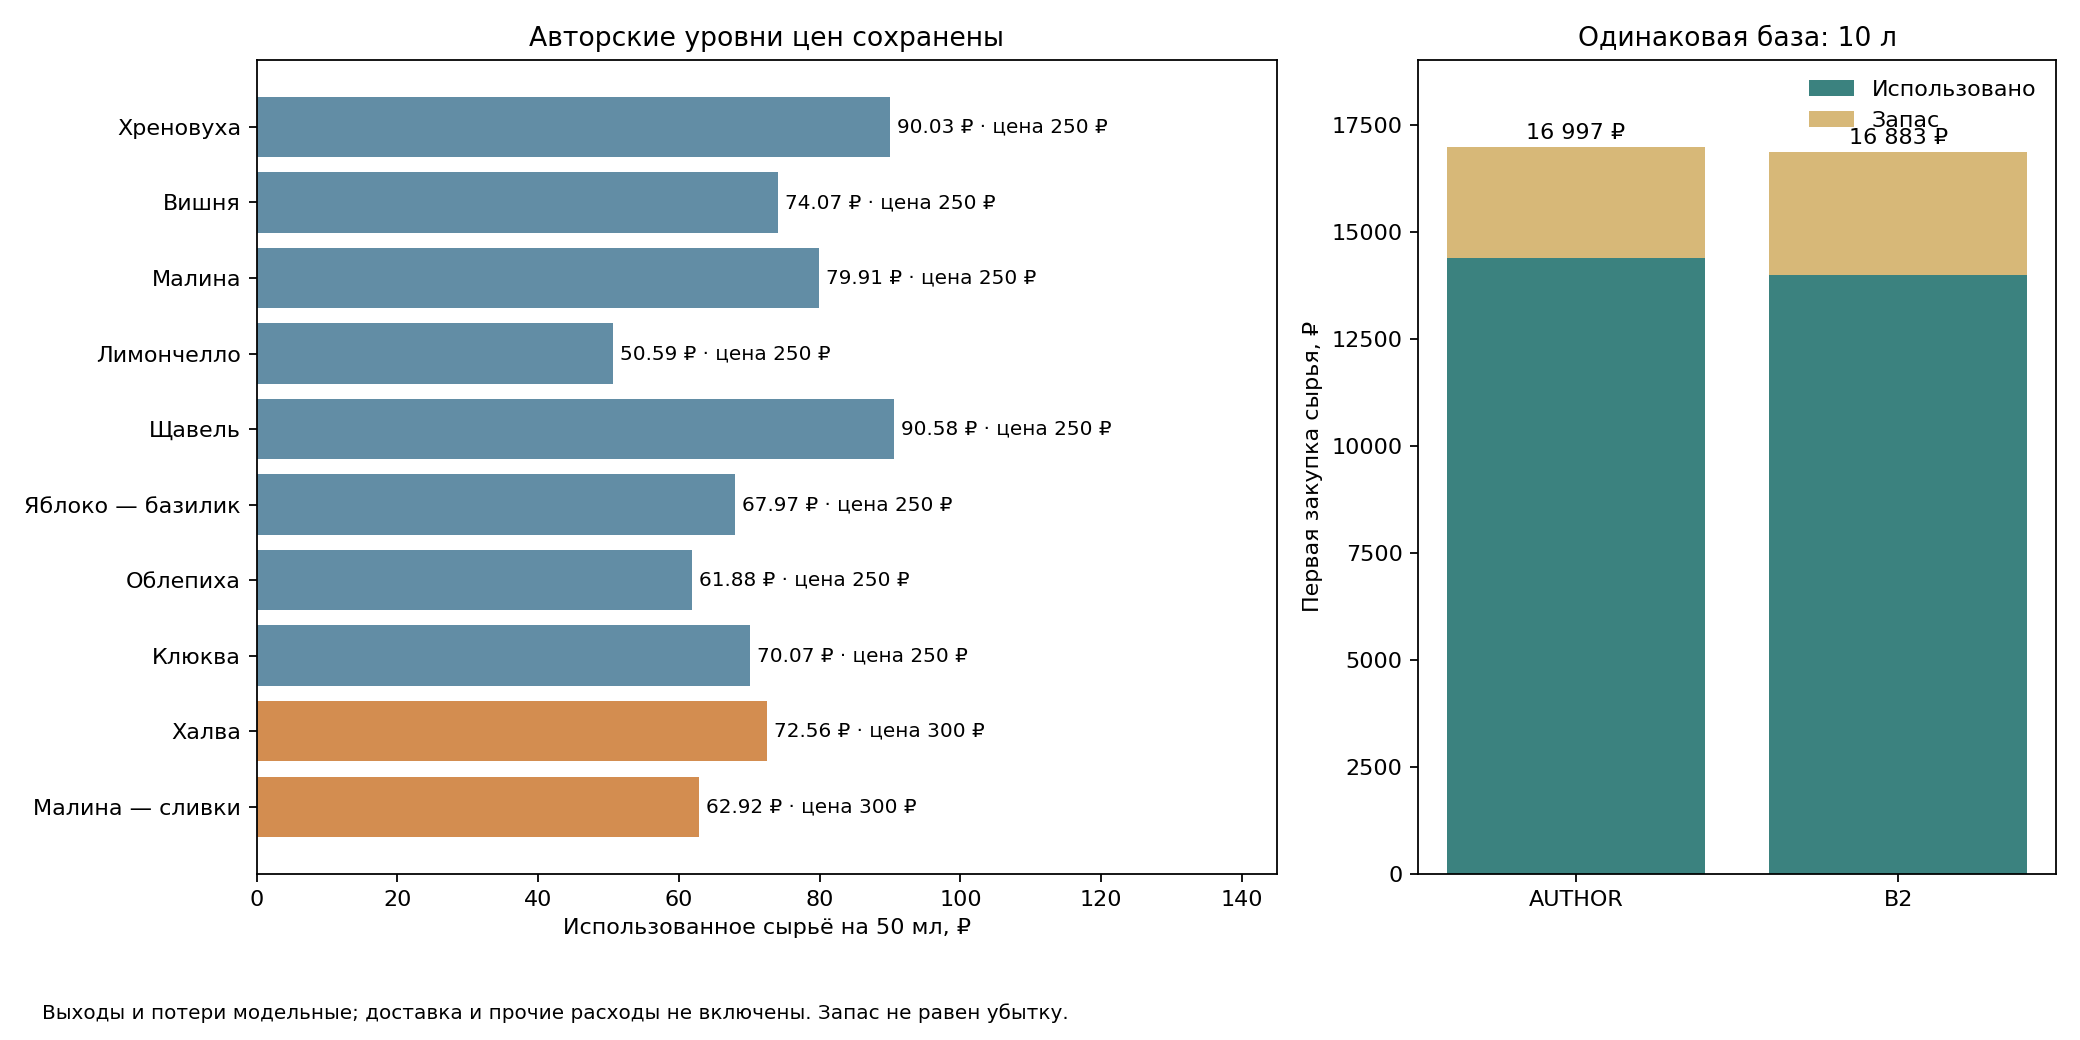

In [10]:
display(author_comparison.set_index("menu")[["purchase_cash_rub","consumed_cost_rub","leftover_value_rub","high_risk_leftover_value_rub","ingredient_count","shared_nonuniversal_count","unique_nonuniversal_count","simple_mean_cost_50ml_rub","base_weighted_price_50ml_rub","base_material_margin_fraction","published_recipe_count","adapted_recipe_count","model_recipe_count"]].T)
display(Image(filename=str(ROOT / "figures/economics/author_economics.png")))

## 10. Что проверить до реального запуска

Состав и уровни цен сохранены. Нужны пробные партии с измерением выхода, потерь, времени, конечной крепости и труда. Отдельно проверить водный баланс/цедру лимончелло, осадок и фильтрацию халвы, устойчивость и безопасную технологию молочной малины. Согласовать региональные поставки, единицы заказа, минимум, доставку и этикетки. Для хранения готового продукта требуются подтверждённые условия — числа не придуманы.

Оценить реальные продажи, списания и восприятие цены предстоит отдельно. Отзывы не представляют всех гостей и не измеряют спрос. Материальный доход не является чистой прибылью. Предварительное авторское меню не объявлено оптимальным или технологически готовым. PR остаётся черновиком; слияние в main не разрешено.

In [11]:
import hashlib
assert e.check_baseline()
for name, digest in history["protected_stage2_sha256"].items():
    assert hashlib.sha256((ROOT/name).read_bytes()).hexdigest() == digest, name
assert set(author_result["selected_ids"]) == a.EXPECTED_BASIC | a.EXPECTED_PREMIUM
assert not author_result["optimizer_called"]
assert author_quantities.shape == (10,21)
assert author_items.yield_status.eq("assumed_unmeasured").all()
print("Состав автора, 8+2, цены, первичная база и исторические результаты сохранены.")

Состав автора, 8+2, цены, первичная база и исторические результаты сохранены.


# Архив подробного анализа этапа 2

Исторические рекомендации ниже относятся к моменту до прямого выбора автора. Текущий состав и цены определены этапом 3 выше. Подробные расчёты и ограничения сохранены для прослеживаемости.

# Nastoyka: разнообразие меню и экономика общей закупки

**Второй этап существующего исследования.** Нужно предложить одному бару Санкт-Петербурга 10 настоек: 8 основных и 2 премиальные. Цель — средняя цена проданной порции 250 ₽ за 50 мл вместо исторического ориентира 200 ₽. Отзывы не заменяют продажи; A/B-тест не проводится.

**Предложение для обсуждения: проверить B2 в пробных партиях**, если приемлемы дополнительные стартовые закупки. Две замены в B усиливают классику и снимают два сильных сигнала похожести. Совместимость сырья и строгая база отзывов при этом ухудшаются. Составы A/B/C сохранены; итоговое меню не утверждено. [Подробный отчёт](docs/economics_report.md) · [Методика](docs/economics_methodology.md) · [План](docs/project_plan.md).

In [12]:
from pathlib import Path
import contextlib, io, json
import pandas as pd
from IPython.display import display, Image, Markdown
from scripts import economics as e
ROOT = Path.cwd()
assert (ROOT / "data/nastoyki_reviews.xlsx").exists(), "Запускайте из корня репозитория"
result = json.loads((ROOT / "data/economics/stage2_baseline.json").read_text())["summary"]
out = ROOT / "data/economics/results"
def read(name): return pd.read_csv(out / name)
candidates = read("candidates.csv")
recipes = read("recipe_costs.csv")
menus = read("menu_summary.csv")
items = read("menu_items.csv")
procurement = read("procurement.csv")
scenarios = read("price_scenarios.csv")
print("Защищённых исходных файлов:", len(e.check_baseline()["protected_files_sha256"]))
print("Кандидатов:", len(candidates), "; рецептур с измеренным выходом:", result["recipes_with_measured_yield"])

Защищённых исходных файлов: 14
Кандидатов: 15 ; рецептур с измеренным выходом: 0


## 1. Данные и пределы свидетельств

Новые отзывы не собираем. Excel и старые CSV не изменяем. Связь «заведение → отзыв → вкус» восстанавливается через SQLite JOIN; SQL сверяется с прежней сводкой. Подтверждённая публикация не доказывает визит; большинство доступны как видимый фрагмент. Неизвестные демографические признаки не восстанавливаются.

reviews                       368
verified_reviews              358
mentions                      468
verified_concrete_mentions    198
verified_flavors              114
strict_mentions               143
menu_rows                      95
current_venues                 30
Name: Прежняя база, dtype: int64

Проверенные публикации с видимым фрагментом: 275


```sql
-- Источник таблиц — исходная Excel-книга; имена и значения не перенормализуются.
-- Строгий срез повторяет scripts/workbook.py: это текущие заведения, НЕ давность отзывов.
CREATE TEMP VIEW verified_concrete AS
SELECT m.*, r.event_group, r.platform_verification, r.bias_flag,
       COALESCE(NULLIF(r.event_group,''), r.review_id) AS event_key,
       CASE WHEN m.confidence='high' AND v.sample_current='yes'
                  AND COALESCE(r.platform_verification,'') <> 'not_passed'
                  AND COALESCE(r.bias_flag,'') = '' THEN 1 ELSE 0 END AS strict_flag
FROM mentions m
JOIN reviews r ON r.review_id=m.review_id AND r.venue_id=m.venue_id
JOIN venues v ON v.venue_id=m.venue_id
WHERE m.source_status='verified' AND r.source_status='verified'
  AND COALESCE(r.duplicate_of,'')='' AND m.specificity='concrete'
  AND COALESCE(m.normalized_flavor,'') <> '';


```

,candidate_id,normalized_flavor,verified_mentions,positive,negative,mixed,unique_events,unique_venues,strict_mentions,strict_positive
0,C01,Хреновуха,7,5,1,1,7,6,6,5
1,C02,Вишня,4,3,0,0,4,4,1,1
2,C03,Малина,6,4,0,0,6,3,5,3
3,C04,Лимончелло,4,4,0,0,4,4,3,3
4,C05,Щавель,7,5,1,0,7,3,7,5
5,C06,Халва,6,5,0,0,6,3,6,5
6,C07,Черника — сыр,6,4,0,1,6,1,3,1
7,C08,Маракуйя,5,4,0,0,5,2,3,2
8,C09,Яблоко — базилик,3,3,0,0,3,1,3,3
9,C10,Свёкла — хрен,3,3,0,0,3,2,2,2


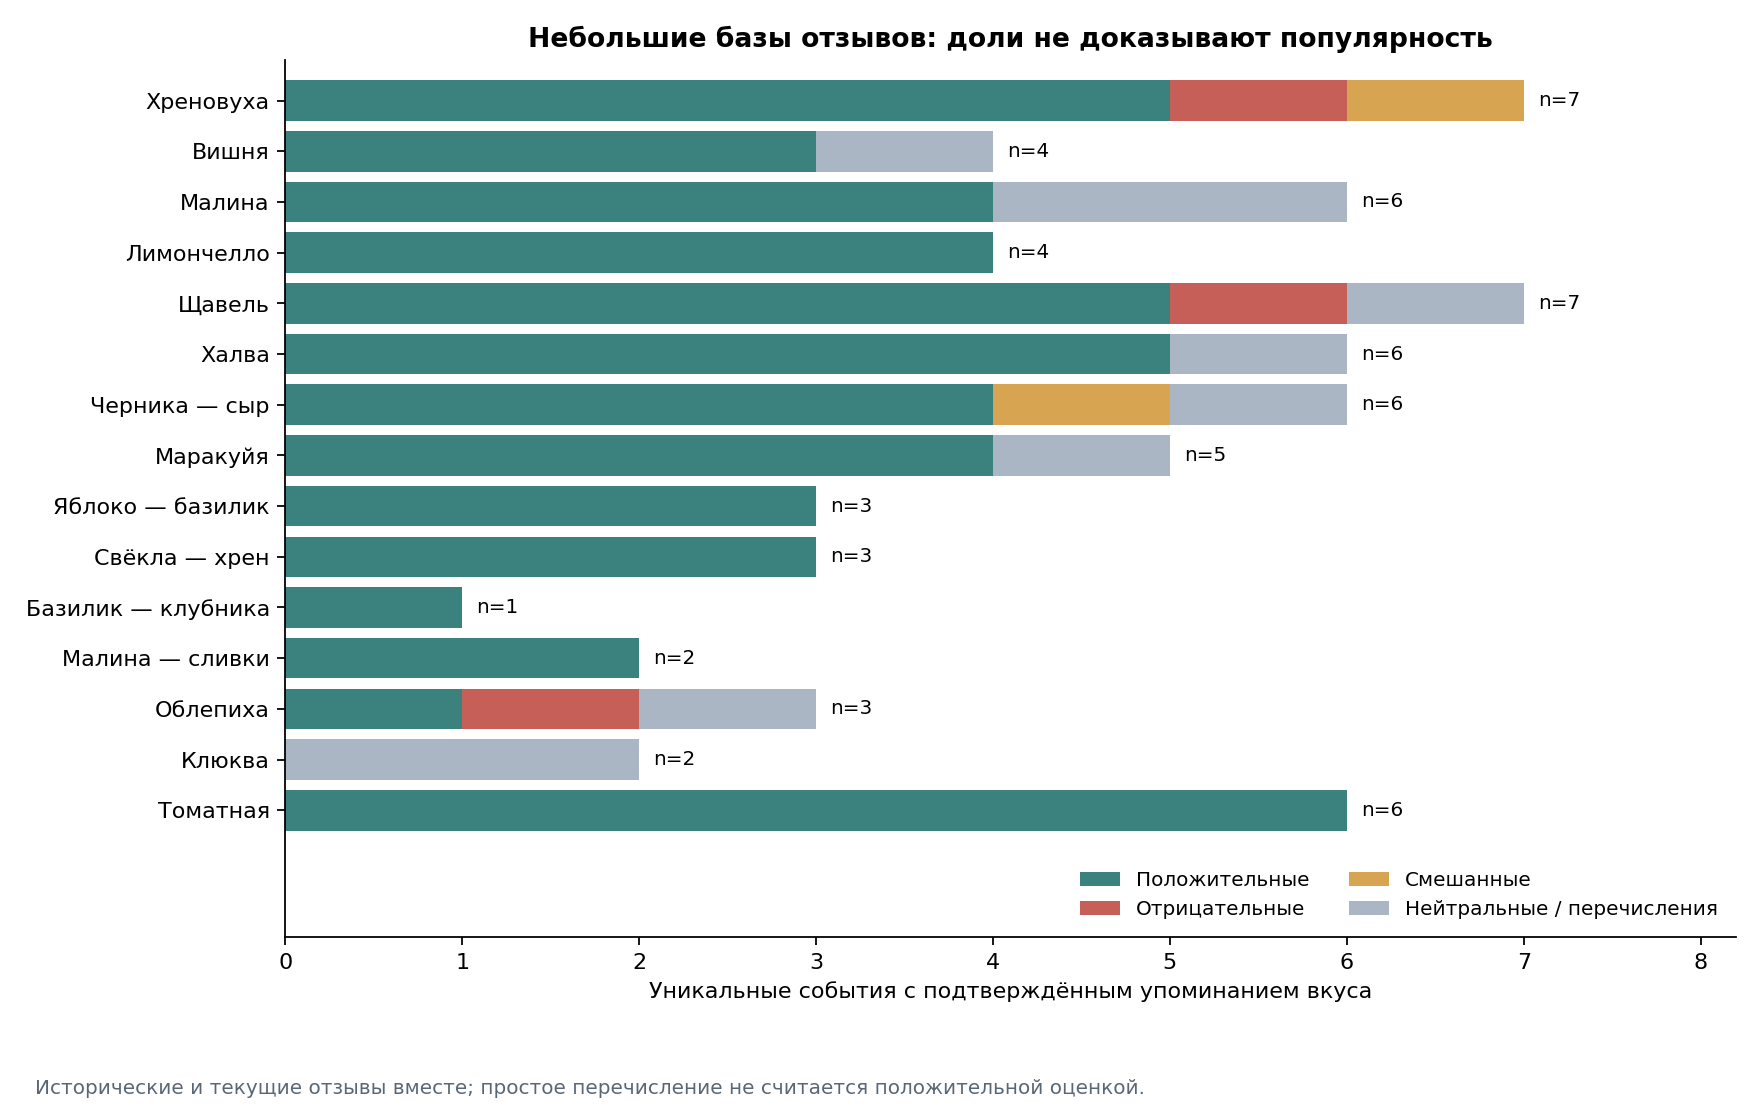

In [13]:
frames = e.workbook_frames()
display(pd.Series(result["source_counts"], name="Прежняя база"))
print("Проверенные публикации с видимым фрагментом:", ((frames["reviews"].source_status == "verified") & (frames["reviews"].text_completeness == "visible_excerpt")).sum())
sql = (ROOT / "scripts/candidates.sql").read_text()
display(Markdown("```sql" + chr(10) + sql.split("-- Один вкус")[0] + chr(10) + "```"))
display(candidates[["candidate_id","normalized_flavor","verified_mentions","positive","negative","mixed","unique_events","unique_venues","strict_mentions","strict_positive"]])
display(Image(filename=str(ROOT / "figures/economics/reviews.png")))

У кандидатов очень небольшие базы. Клюква упомянута трижды в двух событиях, без явно положительного тона. У томатной шесть положительных упоминаний из одного заведения, но только одно в строгом срезе. Строгий срез фильтрует текущее заведение и качество свидетельства, а не свежесть публикации. Покрытие меню ниже считаем объединением событий, а не суммой баз вкусов.

## 2. Вкусовая структура: состав и экспертные гипотезы

Основные роли и classic/unusual — экспертные признаки, отдельно от прежнего словаря. Восемь тегов не доказывают восемь разных дегустационных ощущений. Доминанта, сладость и кислотность всех готовых вариантов неизвестны. Именованные сочетания считаем отдельно от всех необычных позиций: щавель или халва не становятся сочетаниями автоматически.

,candidate_id,normalized_flavor,category,primary_role,classic,unusual,creamy
0,C01,Хреновуха,пряная,пряная,1,0,0
1,C02,Вишня,ягодная,ягодная,1,0,0
2,C03,Малина,ягодная,ягодная,1,0,0
3,C04,Лимончелло,цитрусовая,цитрусовая,1,0,0
4,C05,Щавель,травяная,травяная,0,1,0
5,C06,Халва,десертная,десертная,0,1,0
6,C07,Черника — сыр,ягодная,десертная,0,1,1
7,C08,Маракуйя,фруктовая,фруктовая,0,0,0
8,C09,Яблоко — базилик,фруктовая,фруктовая,0,1,0
9,C10,Свёкла — хрен,пряная,пряная,0,1,0


,candidate_id,flavor_anchors,dominant_sensory_ingredient,sweetness,acidity,dessert_hypothesis,anchor_status
0,C01,horseradish,unknown,unknown,unknown,0,expert_hypothesis_from_model
1,C02,cherry,unknown,unknown,unknown,0,expert_hypothesis_from_model
2,C03,raspberry,unknown,unknown,unknown,0,expert_hypothesis_from_model
3,C04,lemon,unknown,unknown,unknown,1,expert_hypothesis_from_model
4,C05,sorrel,unknown,unknown,unknown,0,expert_hypothesis_from_model
5,C06,halva,unknown,unknown,unknown,1,expert_hypothesis_from_model
6,C07,blueberry|cream_cheese,unknown,unknown,unknown,1,expert_hypothesis_from_model
7,C08,passionfruit,unknown,unknown,unknown,0,expert_hypothesis_from_model
8,C09,apple|basil,unknown,unknown,unknown,0,expert_hypothesis_from_model
9,C10,beet|horseradish,unknown,unknown,unknown,0,expert_hypothesis_from_model


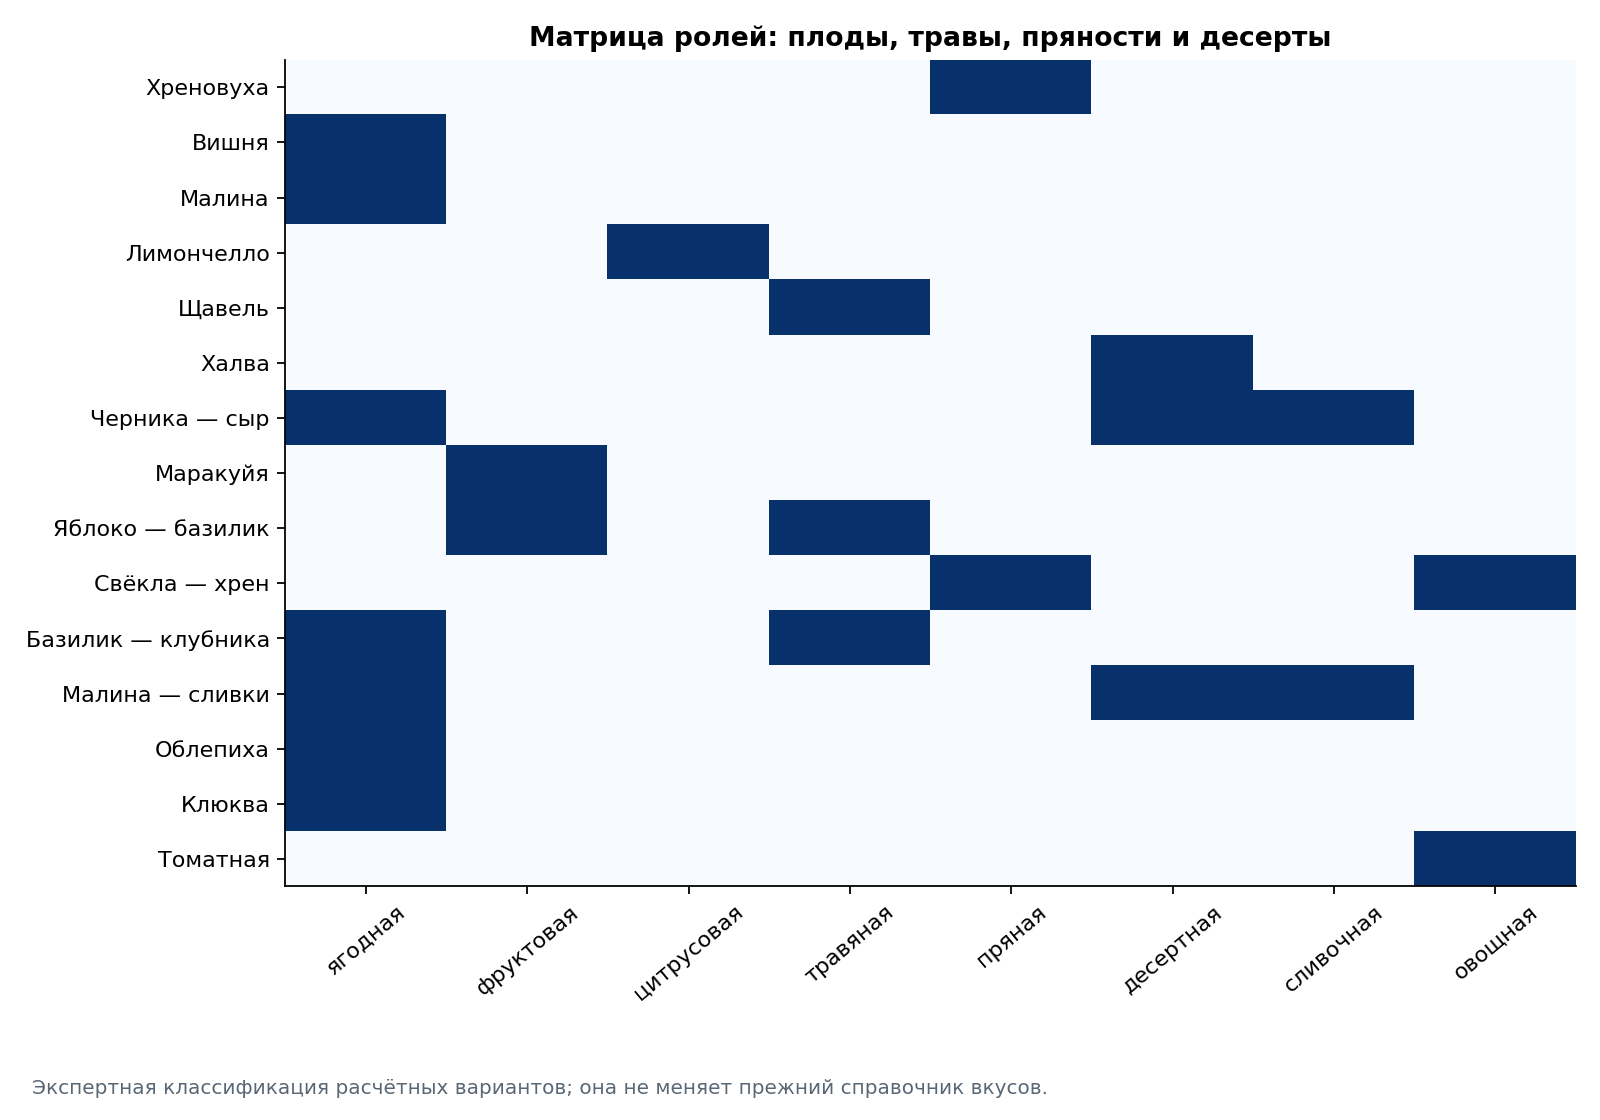

In [14]:
display(candidates[["candidate_id","normalized_flavor","category","primary_role","classic","unusual","creamy"]])
profiles = pd.read_csv(ROOT / "data/economics/flavor_profiles.csv")
display(profiles[["candidate_id","flavor_anchors","dominant_sensory_ingredient","sweetness","acidity","dessert_hypothesis","anchor_status"]])
display(Image(filename=str(ROOT / "figures/economics/flavor_matrix.png")))

### Три пары, которые пропускала прежняя эвристика

Strong — общий ключевой плод или пряный корень; moderate — общий базилик при разных плодах. Background означает только общую основную категорию. У каждой из 105 пар сохранены исходные компоненты, десертный признак и закупочный Jaccard. Водка/сахар/вода исключены. Совпадение компонента — сигнал для дегустации, а не установленный дубль.

In [15]:
pairs = read("flavor_pairs.csv")
display(pairs.loc[pairs.review_flag.isin(["strong","moderate"]), ["candidate_a","candidate_b","shared_anchors","review_flag","same_primary_category","both_dessert_hypothesis","sweetness_comparison","sensory_similarity_measured"]])
assert len(pairs) == 105
assert pairs.sweetness_comparison.eq("unknown").all()
assert not pairs.sensory_similarity_measured.any()

,candidate_a,candidate_b,shared_anchors,review_flag,same_primary_category,both_dessert_hypothesis,sweetness_comparison,sensory_similarity_measured
8,C01,C10,horseradish,strong,True,False,unknown,False
35,C03,C12,raspberry,strong,False,False,unknown,False
85,C09,C11,basil,moderate,False,False,unknown,False


## 3. Аудит всех рецептур

Четыре опубликованных количественных состава, четыре адаптации, семь моделей. Ни один выход не измерен. Найдены дополнительные аналоги для нескольких моделей, но иная основа, единицы или ингредиенты не подтверждают текущую дозировку. Происхождение модели не переписано на новый источник. Конечная крепость, стабильность и безопасное хранение не установлены. Время приготовления не является сроком хранения.

In [16]:
recipe_audit = pd.read_csv(ROOT / "data/economics/recipe_audit.csv").fillna("")
display(recipe_audit[["candidate_id","flavor","composition_status","yield_status","source_url","additional_reference_url","checked_at","shelf_life_status"]])
display(recipe_audit[["candidate_id","additional_reference_finding","checks_required"]])
print(recipe_audit.composition_status.value_counts().to_dict())
assert recipe_audit.shelf_life_days.eq("").all()
assert recipe_audit.final_abv_status.eq("unknown_not_calculated").all()

,candidate_id,flavor,composition_status,yield_status,source_url,additional_reference_url,checked_at,shelf_life_status
0,C01,Хреновуха,model_adaptation,assumed_unmeasured,https://www.iamcook.ru/showrecipe/26613,,2026-10-15,not_established
1,C02,Вишня,model_adaptation,assumed_unmeasured,https://www.edimdoma.ru/retsepty/60273-vishnev...,,2026-10-15,not_established
2,C03,Малина,model_adaptation,assumed_unmeasured,https://alcofan.com/recepty-nastoek-maliny-na-...,,2026-10-15,not_established
3,C04,Лимончелло,model_adaptation,assumed_unmeasured,https://alcofan.com/prigotovlenie-domashnego-l...,,2026-10-15,not_established
4,C05,Щавель,published_quantities,assumed_unmeasured,https://alcofan.com/kak-sdelat-nastojku-iz-shh...,,2026-10-15,not_established
5,C06,Халва,published_quantities,assumed_unmeasured,https://www.rbc.ru/wine/news/6718b1f19a7947d25...,,2026-10-15,not_established
6,C07,Черника — сыр,model_only,assumed_unmeasured,,,2026-10-15,not_established
7,C08,Маракуйя,model_only,assumed_unmeasured,,https://therumdiary.ru/reczepty-podpischikov/n...,2026-10-15,not_established
8,C09,Яблоко — базилик,model_only,assumed_unmeasured,,https://www.iamcook.ru/showrecipe/34036,2026-10-15,not_established
9,C10,Свёкла — хрен,model_only,assumed_unmeasured,,https://povar.ru/recipes/svekolnaya_nastoika-9...,2026-10-15,not_established


,candidate_id,additional_reference_finding,checks_required
0,C01,Исходная количественная информация повторно пр...,"Проверить 60 г корня, пересчёт мёда из ложек, ..."
1,C02,Исходная количественная информация повторно пр...,В источнике нет массы вишни; подтвердить дозир...
2,C03,Исходная количественная информация повторно пр...,Дозировки сильно отличаются от источника; подт...
3,C04,Исходная количественная информация повторно пр...,Взвесить целые лимоны и выход цедры; число пло...
4,C05,Исходная количественная информация повторно пр...,"Проверить экстракцию щавеля, осадок, цвет и фи..."
5,C06,Исходная количественная информация повторно пр...,Подтвердить вид халвы: подсолнечная выбрана эк...
6,C07,Поиски черника+сыр дали несопоставимые блюда; ...,"Подтвердить выбор творожного сыра, эмульсию, о..."
7,C08,Пользовательский количественный аналог: 500 мл...,"Проверить состав пюре, наличие добавленного са..."
8,C09,Найден яблочный аналог без базилика; он не под...,Проверить дозировку базилика; замороженный ябл...
9,C10,Свекольный аналог без хрена; 400 г свёклы и 75...,Проверить восприятие хрена против свёклы; цвет...


{'model_only': 7, 'model_adaptation': 4, 'published_quantities': 4}


## 4. Закупочные источники и единицы

Все 21 страницы перечитаны 15.10.2026. Существенное уточнение: хрен 900 ₽ за 500 г, прежде 1 900 ₽/кг с неподтверждённым шагом. Прочие выбранные цены найдены повторно. У базилика, щавеля и лимона примерно 100 г, у ягод фасовки 1 кг; наличие и продажа отдельной упаковки требуют подтверждения. У пяти товаров ВкусВилла не выбран адрес. Сыр — 248 ₽/150 г без условной скидки 159 ₽. Сливки — 152 ₽/450 мл, не граммов. Доставка Дарим Лето опубликована от 500 ₽, что все четыре корзины проходят по этому поставщику; иные условия остаются частично неизвестными.

In [17]:
price_audit = pd.read_csv(ROOT / "data/economics/ingredient_audit.csv").fillna("")
display(price_audit[["ingredient_id","current_price_rub","current_quantity","current_unit","SPb_availability","stock_status","order_unit_status","supplier_minimum_status","url","checked_at"]])
print("Проверено ценовых страниц:", len(price_audit))
assert price_audit.check_status.eq("live_page_read").all()

,ingredient_id,current_price_rub,current_quantity,current_unit,SPb_availability,stock_status,order_unit_status,supplier_minimum_status,url,checked_at
0,vodka,726,500,ml,SPb_service_published,seller_says_confirm_availability,published_package,unknown,https://spb.decanter.ru/vodka/05-l,2026-10-15
1,sugar,71,1,kg,SPb_service_published,conflicting_preorder_and_in_stock,published_package,unknown,https://aquabalt.ru/catalog/k-chayu/saharnyy-p...,2026-10-15
2,water,117,5,l,address_not_selected,address_selection_required,published_package,unknown,https://vkusvill.ru/goods/voda-pitevaya-negazi...,2026-10-15
3,honey,274,200,g,address_not_selected,address_selection_required,published_package,unknown,https://vkusvill.ru/goods/med-tsvetochnyy-mays...,2026-10-15
4,horseradish,900,500,g,SPb_service_published,public_cart_available,published_sales_unit,unknown,https://multifrukt-spb.ru/products/246,2026-10-15
5,lemon,20,100,g,SPb_service_published,seller_states_in_stock,approximate_weight_step,unknown,https://frutstar.ru/fruits/citrusovye/limony,2026-10-15
6,cherry,572,1,kg,SPb_service_published,catalog_cart_not_stock_guarantee,published_package,delivery_order_at_least_500_RUB_published,https://darim-leto.ru/catalog/vishnya,2026-10-15
7,raspberry,838,1,kg,SPb_service_published,catalog_cart_not_stock_guarantee,published_package,delivery_order_at_least_500_RUB_published,https://darim-leto.ru/catalog/malina,2026-10-15
8,sorrel,99,100,g,SPb_service_published,seller_states_in_stock,approximate_weight_step,unknown,https://frutstar.ru/greens/zelen/schavel,2026-10-15
9,halva,83,250,g,address_not_selected,address_selection_required,published_package,unknown,https://vkusvill.ru/goods/khalva-podsolnechnay...,2026-10-15


Проверено ценовых страниц: 21


## 5. Себестоимость при неизмеренном выходе

`ready_ml = nominal_product_ml × (1 − loss_fraction)`; `cost_50ml = batch_cost / ready_ml × 50`.

Номинальный жидкий объём — допущение, не сумма г и мл. Стоимость сырья включает потери, которые уменьшают пригодный выход без повторного списания. Для закупок все позиции масштабируются к 1 л, всего 10 л на меню. Это база сравнения, а не прогноз спроса. Дозировки сахара/мёда ниже не равны сенсорной сладости. Материальная маржа не включает прочие расходы бара.

,candidate_id,normalized_flavor,nominal_product_ml,loss_fraction,ready_ml,cost_50ml_rub,model_added_sugar_g_per_l,model_honey_g_per_l,sensory_sweetness_status,material_margin_fraction
0,C01,Хреновуха,520,0.08,478.4,90.029264,0.000000,41.806020,unknown_not_measured,0.608568
1,C02,Вишня,700,0.10,630.0,74.071429,158.730159,0.000000,unknown_not_measured,0.677950
2,C03,Малина,700,0.12,616.0,79.910714,162.337662,0.000000,unknown_not_measured,0.652562
3,C04,Лимончелло,1240,0.05,1178.0,50.586587,339.558574,0.000000,unknown_not_measured,0.780058
4,C05,Щавель,590,0.10,531.0,90.583804,0.000000,188.323917,unknown_not_measured,0.606157
5,C06,Халва,850,0.15,722.5,72.560554,0.000000,124.567474,unknown_not_measured,0.780120
6,C07,Черника — сыр,900,0.15,765.0,83.061438,130.718954,0.000000,unknown_not_measured,0.748299
7,C08,Маракуйя,950,0.10,855.0,60.304678,116.959064,0.000000,unknown_not_measured,0.817259
8,C09,Яблоко — базилик,720,0.10,648.0,67.965278,123.456790,0.000000,unknown_not_measured,0.704499
9,C10,Свёкла — хрен,650,0.10,585.0,70.055556,0.000000,34.188034,unknown_not_measured,0.695411


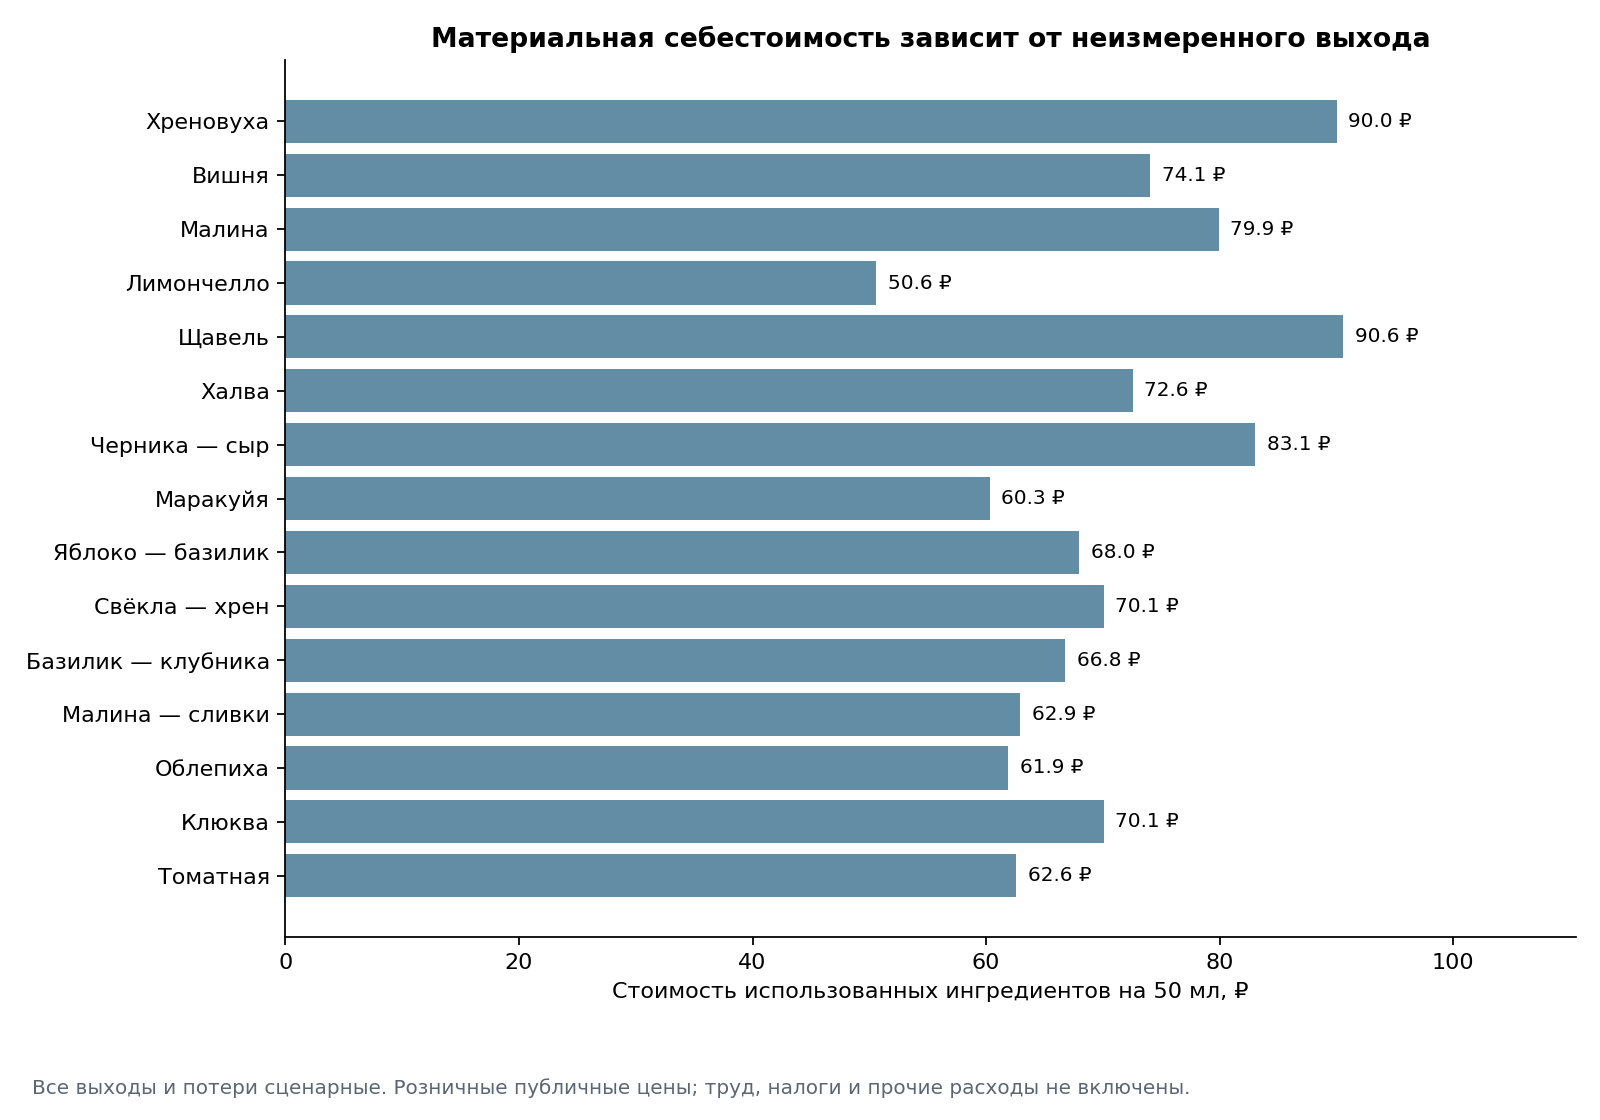

In [18]:
display(recipes[["candidate_id","normalized_flavor","nominal_product_ml","loss_fraction","ready_ml","cost_50ml_rub","model_added_sugar_g_per_l","model_honey_g_per_l","sensory_sweetness_status","material_margin_fraction"]])
display(Image(filename=str(ROOT / "figures/economics/costs.png")))
assert recipes.yield_status.eq("assumed_unmeasured").all()

## 6. Сохранённые A/B/C и новая B2

Составы и прежние входы зафиксированы по коммиту `09fb89200c90ed51c374d8d2bd6ffc20b425f3f9` в stage1_baseline.json. Прежние корзины A/B/C: 16 993 / 17 009 / 18 311 ₽. Обновление хрена снижает каждую на 1 000 ₽; ниже одинаковые цены для всех меню. Название A как минимальной корзины относится к прежнему отбору.

B2: **малина → вишня; свёкла — хрен → облепиха**. Премиальная пара B сохраняется: халва и малина — сливки. Приоритеты B2 заданы экспертно: вишня, минимум четыре классики, ноль сильных пересечений, прежние роли, 8+2 и финансовые ограничения. Балл для нового выбора не используется.

**Меню A**

,candidate_id,normalized_flavor,tier,price_rub,cost_50ml_rub
0,C01,Хреновуха,basic,230,90.029264
1,C03,Малина,basic,230,79.910714
2,C04,Лимончелло,basic,230,50.586587
3,C05,Щавель,basic,230,90.583804
4,C06,Халва,premium,330,72.560554
5,C09,Яблоко — базилик,basic,230,67.965278
6,C10,Свёкла — хрен,basic,230,70.055556
7,C12,Малина — сливки,premium,330,62.921983
8,C13,Облепиха,basic,230,61.883878
9,C15,Томатная,basic,230,62.598431


**Меню B**

,candidate_id,normalized_flavor,tier,price_rub,cost_50ml_rub
10,C01,Хреновуха,basic,230,90.029264
11,C03,Малина,basic,230,79.910714
12,C04,Лимончелло,basic,230,50.586587
13,C05,Щавель,basic,230,90.583804
14,C06,Халва,premium,330,72.560554
15,C09,Яблоко — базилик,basic,230,67.965278
16,C10,Свёкла — хрен,basic,230,70.055556
17,C11,Базилик — клубника,basic,230,66.784091
18,C12,Малина — сливки,premium,330,62.921983
19,C15,Томатная,basic,230,62.598431


**Меню C**

,candidate_id,normalized_flavor,tier,price_rub,cost_50ml_rub
20,C01,Хреновуха,basic,230,90.029264
21,C03,Малина,basic,230,79.910714
22,C04,Лимончелло,basic,230,50.586587
23,C05,Щавель,basic,230,90.583804
24,C06,Халва,premium,330,72.560554
25,C07,Черника — сыр,premium,330,83.061438
26,C09,Яблоко — базилик,basic,230,67.965278
27,C10,Свёкла — хрен,basic,230,70.055556
28,C11,Базилик — клубника,basic,230,66.784091
29,C15,Томатная,basic,230,62.598431


**Меню B2**

,candidate_id,normalized_flavor,tier,price_rub,cost_50ml_rub
30,C01,Хреновуха,basic,230,90.029264
31,C02,Вишня,basic,230,74.071429
32,C04,Лимончелло,basic,230,50.586587
33,C05,Щавель,basic,230,90.583804
34,C06,Халва,premium,330,72.560554
35,C09,Яблоко — базилик,basic,230,67.965278
36,C11,Базилик — клубника,basic,230,66.784091
37,C12,Малина — сливки,premium,330,62.921983
38,C13,Облепиха,basic,230,61.883878
39,C15,Томатная,basic,230,62.598431


,menu,purchase_cash_rub,consumed_cost_rub,leftover_value_rub,high_risk_leftover_value_rub,classic_count,unusual_combination_count,unusual_count,strong_overlap_pairs,moderate_overlap_pairs
0,A,15993.0,14181.920985,1811.079015,923.692406,4,3,6,2,0
1,B,16009.0,14279.925246,1729.074754,855.737860,3,4,7,2,1
2,C,17311.0,14682.714345,2628.285655,956.362935,3,4,7,1,1
3,B2,16883.0,13999.705978,2883.294022,919.985724,4,3,6,0,1


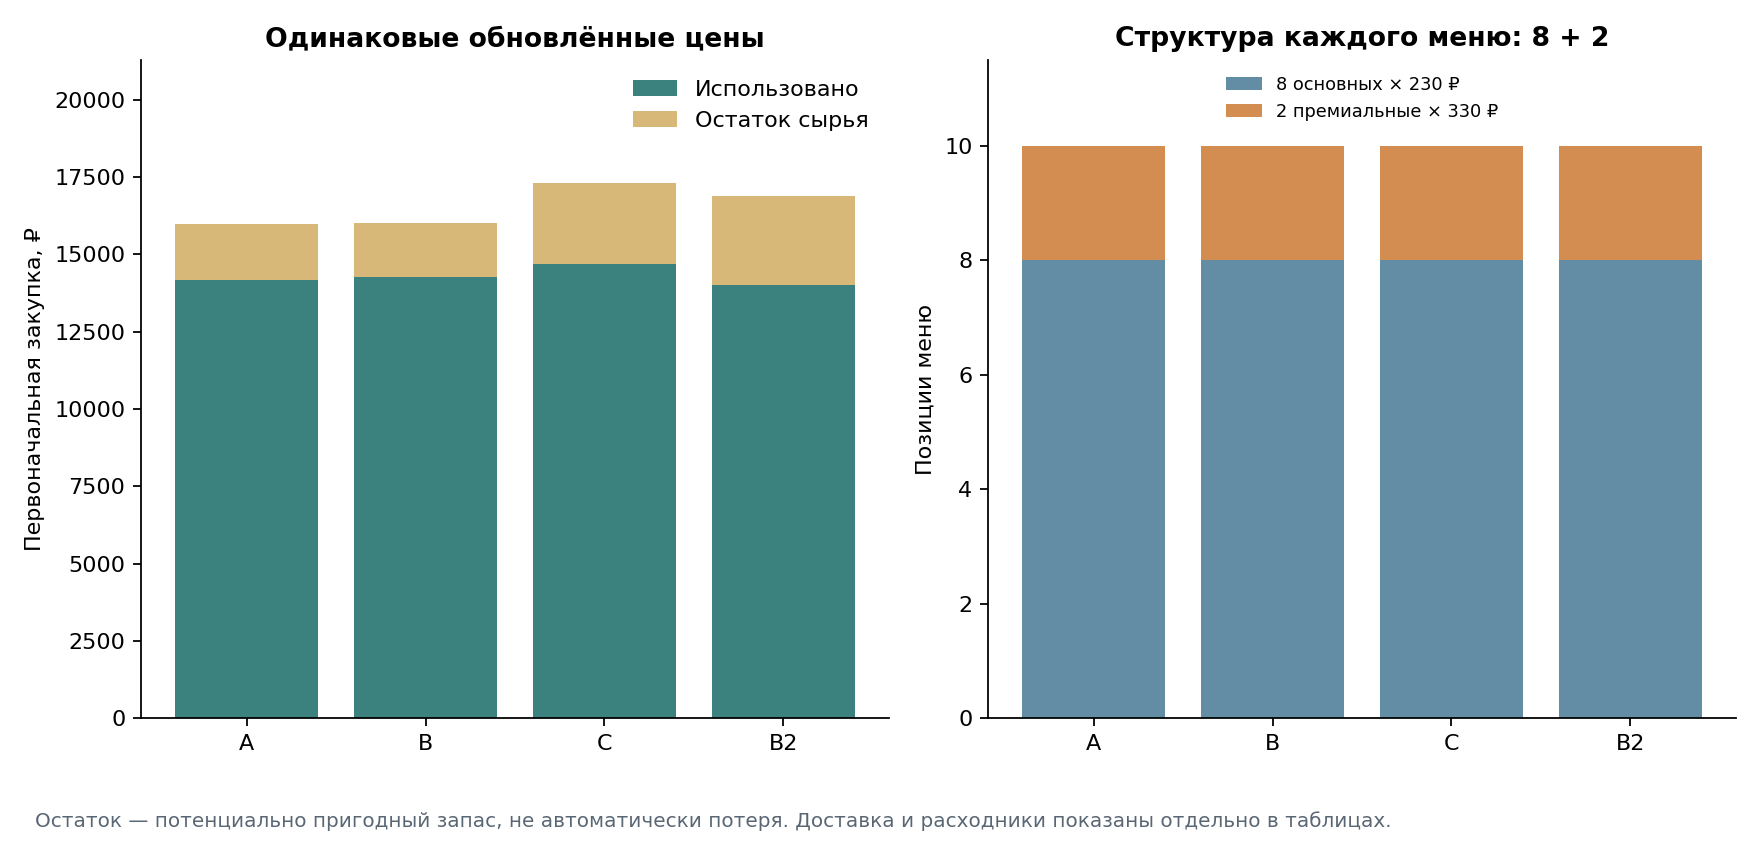

In [19]:
for name in ["A","B","C","B2"]:
    display(Markdown("**Меню " + name + "**"))
    display(items.loc[items.menu.eq(name), ["candidate_id","normalized_flavor","tier","price_rub","cost_50ml_rub"]])
display(menus[["menu","purchase_cash_rub","consumed_cost_rub","leftover_value_rub","high_risk_leftover_value_rub","classic_count","unusual_combination_count","unusual_count","strong_overlap_pairs","moderate_overlap_pairs"]])
display(Image(filename=str(ROOT / "figures/economics/procurement_and_tiers.png")))

### Десять критериев и компромиссы

B2 даёт больше классики и снимает два сильных сигнала, но оставляет умеренную базиликовую пару. Число основных направлений одинаково. Опора на строгие свидетельства и совместимость сырья ухудшаются; первая касса выше, расход ниже. Все неизмеренные выходы остаются ограничением. Таблица не сводится в общий рейтинг.

In [20]:
key_columns = ["direction_tags","primary_roles","strong_overlap_pairs","moderate_overlap_pairs","classic_count","unusual_combination_count","unusual_count","verified_event_count","strict_event_count","verified_mentions_rows","strict_mentions_rows","purchase_cash_rub","consumed_cost_rub","high_risk_leftover_value_rub","shared_nonuniversal_fraction","published_recipe_count","adaptation_recipe_count","model_only_recipe_count","unmeasured_yield_count"]
display(menus.set_index("menu").loc[["B","B2"], key_columns].T)
display(scenarios.loc[scenarios.menu.isin(["B","B2"]) & scenarios.price_pair.eq(0) & scenarios.scenario.eq("base"), ["menu","material_margin_50ml_rub","material_margin_fraction"]])
display(read("menu_alternatives.csv")[["alternative","removed","added","purchase_cash_rub","consumed_cost_rub","classic_count","strong_overlap_pairs","moderate_overlap_pairs","expensive_specific_recipes","passes_expensive_limit"]])

menu,B,B2
direction_tags,8.000000,8.000000
primary_roles,8.000000,8.000000
strong_overlap_pairs,2.000000,0.000000
moderate_overlap_pairs,1.000000,1.000000
classic_count,3.000000,4.000000
unusual_combination_count,4.000000,3.000000
unusual_count,7.000000,6.000000
verified_event_count,38.000000,39.000000
strict_event_count,30.000000,28.000000
verified_mentions_rows,45.000000,43.000000


,menu,material_margin_50ml_rub,material_margin_fraction
10,B,178.600374,0.714401
28,B2,180.001470,0.720006


,alternative,removed,added,purchase_cash_rub,consumed_cost_rub,classic_count,strong_overlap_pairs,moderate_overlap_pairs,expensive_specific_recipes,passes_expensive_limit
0,B,NaN,NaN,16009.0,14279.925246,3,2,1,0,True
1,cherry_for_beet,C10,C02,16603.0,14360.242707,4,1,1,1,True
2,cherry_for_raspberry,C03,C02,16581.0,14163.139532,3,1,1,1,True
3,B2,C03|C10,C02|C13,16883.0,13999.705978,4,0,1,2,True
4,no_basil_pair,C03|C10|C11,C02|C13|C14,17172.0,14065.452731,5,0,0,3,False


Удаление также клубники с базиликом в пользу клюквы снимает умеренную пару, но повышает стартовую кассу до 17 172 ₽ и требует трёх дорогих специфичных рецептур вместо допустимых двух. Порог зависит от фасовок и экспертный; это превышение условия модели, а не доказанная невыгодность. Маракуйя требует смены премиальной пары и проверки отдельного пюре. Черника с сыром остаётся альтернативой C, с одной площадкой происхождения мнений и модельной молочной технологией. Неучастие кандидата в B2 не означает слабый спрос.

### Проверка прежних весов

Предыдущий B использовал экспертные веса 0,35/0,25/0,20/0,20 (отзывы/направления/совместимость/касса). Проверяем 80 точек сетки с каждым весом от 0,1 до 0,6, сумма 1, плюс исходные. Эта эвристика вообще не учитывает сильные пары или усиление классики, поэтому устойчивость её победителя не решает ассортиментную задачу второго этапа.

In [21]:
weights = read("legacy_weight_sensitivity.csv")
display(weights.groupby(["selected"]).size().rename("Число наборов весов"))
display(weights.loc[weights.method.eq("original_legacy_weights_current_prices")])
assert len(weights) == 81
print("B выигрывает при всех проверенных весах старой цели. B2 выбран по открыто заданным ассортиментным приоритетам, а не этому баллу.")

selected
C01|C03|C04|C05|C06|C09|C10|C11|C12|C15    81
Name: Число наборов весов, dtype: int64

,review_weight,diversity_weight,sharing_weight,cash_weight,selected,cash_rub,method
80,0.35,0.25,0.2,0.2,C01|C03|C04|C05|C06|C09|C10|C11|C12|C15,16009.0,original_legacy_weights_current_prices


B выигрывает при всех проверенных весах старой цели. B2 выбран по открыто заданным ассортиментным приоритетам, а не этому баллу.


## 7. Потребность, касса, остатки и риск

Сначала суммируется потребность нескольких настоек, потом округляется общий заказ. Все количества ниже на 10 л сценарного выхода. Базилик одинаков в B/B2; малина в B2 используется только сливочной позицией, поэтому её остаток растёт. Высокий риск — экспертная характеристика сырья, не вероятность порчи. Замороженные остатки также требуют холодовой цепи. Закупка не является готовой заявкой.

,menu,ingredient_id,needed_base_quantity,base_unit,packages,purchase_cash_rub,consumed_cost_rub,leftover_base_quantity,leftover_value_rub
19,B,horseradish,176.700111,g,1,900.0,318.060201,323.299889,581.939799
21,B,raspberry,845.864662,g,1,838.0,708.834586,154.135338,129.165414
25,B,basil,45.875421,g,1,299.0,137.167508,54.124579,161.832492
28,B,cream,239.234450,ml,1,152.0,80.808081,210.765550,71.191919
50,B2,horseradish,125.418060,g,1,900.0,225.752508,374.581940,674.247492
52,B2,cherry,555.555556,g,1,572.0,317.777778,444.444444,254.222222
53,B2,raspberry,358.851675,g,1,838.0,300.717703,641.148325,537.282297
57,B2,basil,45.875421,g,1,299.0,137.167508,54.124579,161.832492
59,B2,cream,239.234450,ml,1,152.0,80.808081,210.765550,71.191919
60,B2,sea_buckthorn,710.227273,g,1,280.0,198.863636,289.772727,81.136364


,menu,cash_three_cycles_average_rub,additional_cash_second_cycle_rub,cash_with_optional_scenarios_rub
0,A,14893.666667,14545.0,17693.0
1,B,15152.666667,14561.0,17709.0
2,C,15741.333333,13819.0,19011.0
3,B2,14983.666667,13849.0,18583.0


,menu,ingredient_id,assumed_order_step,base_unit,purchase_cash_rub,delta_cash_rub,status
0,A,horseradish,100.0,g,15453.0,-540.0,assumed_availability_at_same_published_per_kg_...
1,B,horseradish,100.0,g,15469.0,-540.0,assumed_availability_at_same_published_per_kg_...
2,C,horseradish,100.0,g,16771.0,-540.0,assumed_availability_at_same_published_per_kg_...
3,B2,horseradish,100.0,g,16343.0,-540.0,assumed_availability_at_same_published_per_kg_...


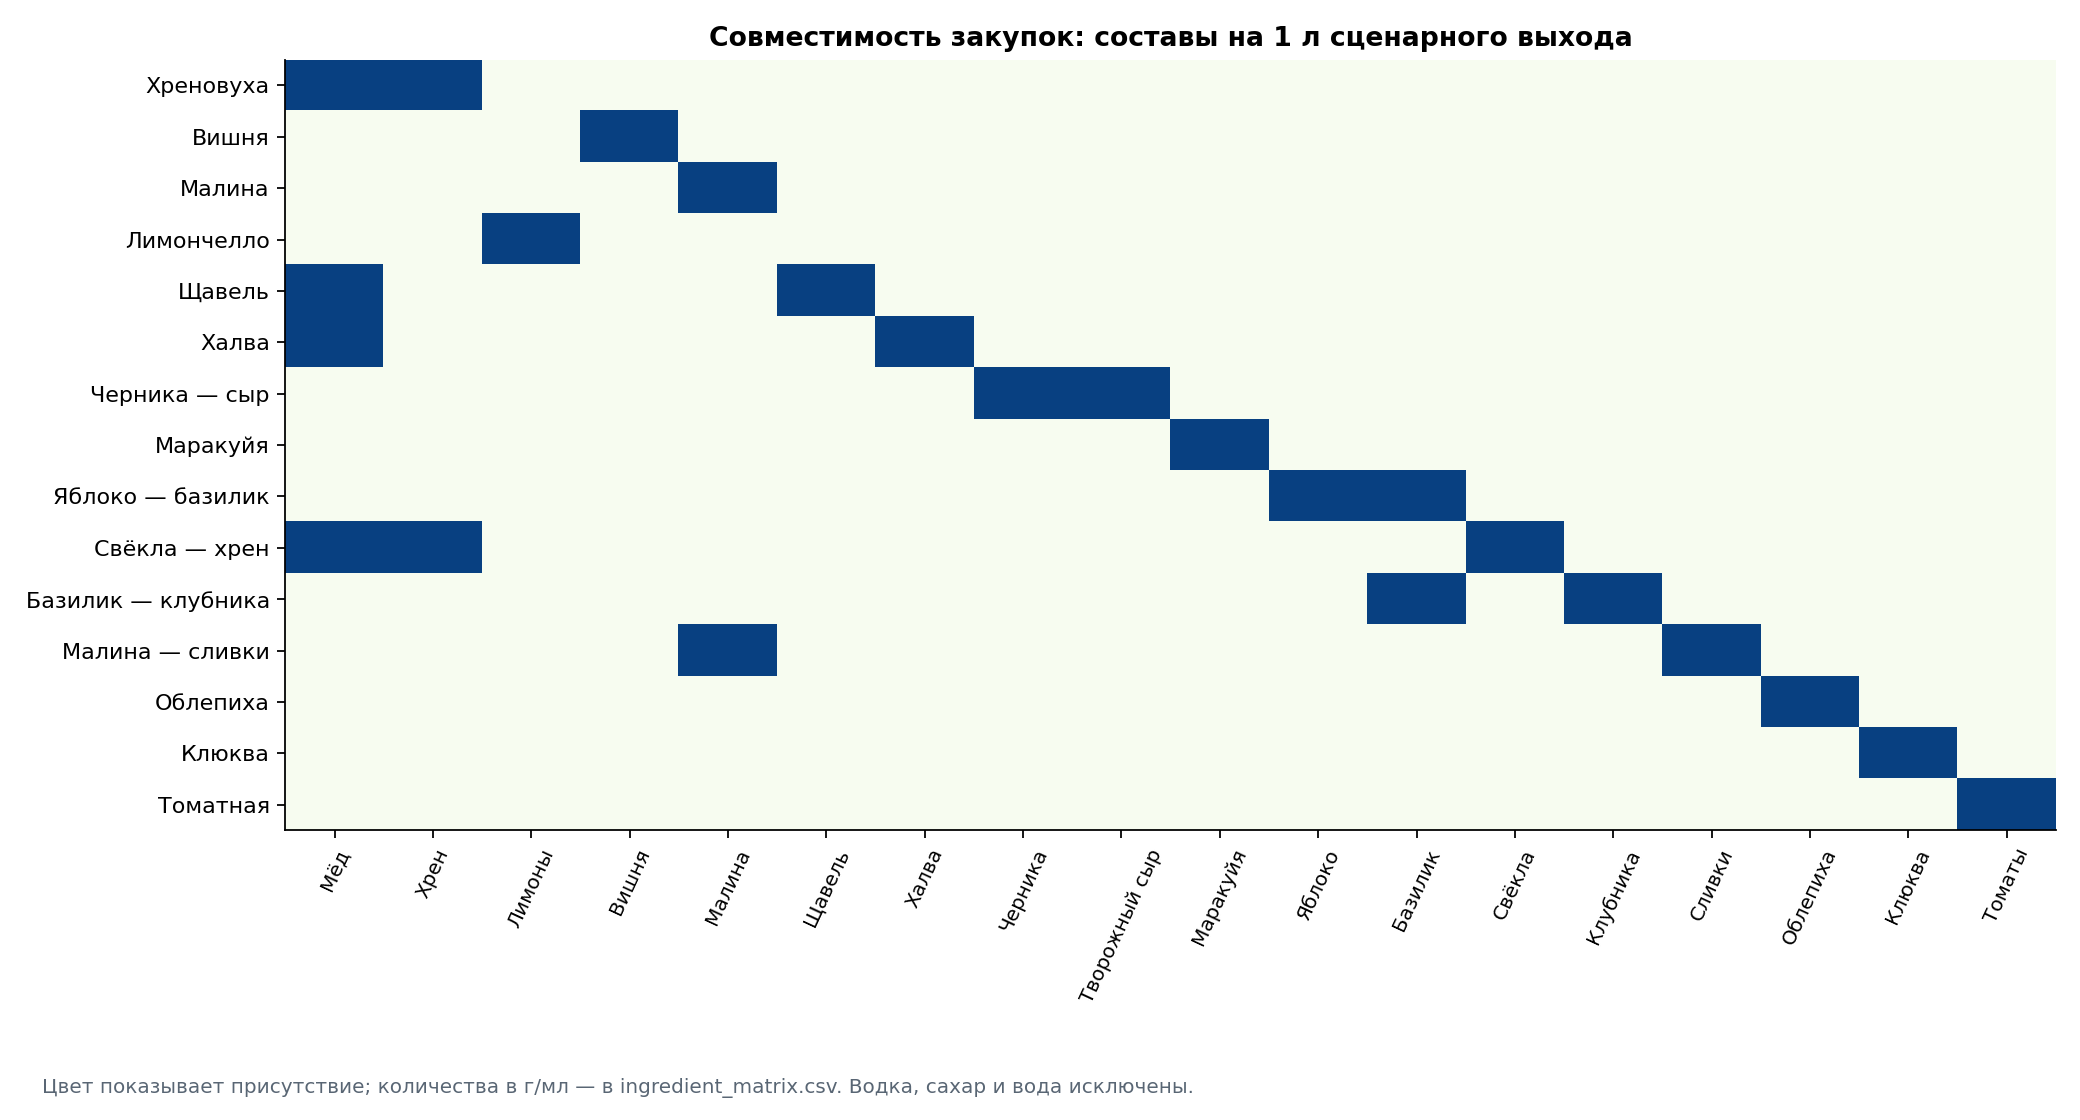

In [22]:
critical = procurement.menu.isin(["B","B2"]) & procurement.ingredient_id.isin(["horseradish","basil","raspberry","cherry","sea_buckthorn","cream_cheese","cream"])
display(procurement.loc[critical, ["menu","ingredient_id","needed_base_quantity","base_unit","packages","purchase_cash_rub","consumed_cost_rub","leftover_base_quantity","leftover_value_rub"]])
display(menus[["menu","cash_three_cycles_average_rub","additional_cash_second_cycle_rub","cash_with_optional_scenarios_rub"]])
display(read("packaging_scenario.csv"))
display(Image(filename=str(ROOT / "figures/economics/ingredient_use.png")))

B2 увеличивает общий запас на 1 154,22 ₽, включая малиновый остаток 641,15 г против 154,14 г у B. Запас не равен потере; повторные циклы предполагают его пригодность. Отпуск хрена по 100 г мог бы снизить кассу на 540 ₽, но такой отпуск не подтверждён. Доставка/расходники +1 700 ₽ на меню — иллюстрация из прежней модели, не найденные тарифы.

## 8. Цена меню, проданная порция и материальная маржа

Простая средняя 8+2 равна 250 ₽. Проданная порция: `(1−p)×230 + p×330`; нужны 20% премиальных продаж. При p=5/20/35% средние цены 235/250/265 ₽. Равные доли позиций внутри уровня — допущение. Из отзывов доли продаж не выводились.

,menu,scenario,premium_share,simple_menu_price_rub,weighted_price_rub,weighted_material_cost_50ml_rub,material_margin_50ml_rub,material_margin_fraction,sales_status
9,B,low,0.05,250.0,235.0,72.085568,162.914432,0.693253,scenario_not_observed
10,B,base,0.20,250.0,250.0,71.399626,178.600374,0.714401,scenario_not_observed
11,B,high,0.35,250.0,265.0,70.713684,194.286316,0.733156,scenario_not_observed
27,B2,low,0.05,250.0,235.0,70.421766,164.578234,0.700333,scenario_not_observed
28,B2,base,0.20,250.0,250.0,69.998530,180.001470,0.720006,scenario_not_observed
29,B2,high,0.35,250.0,265.0,69.575293,195.424707,0.737452,scenario_not_observed


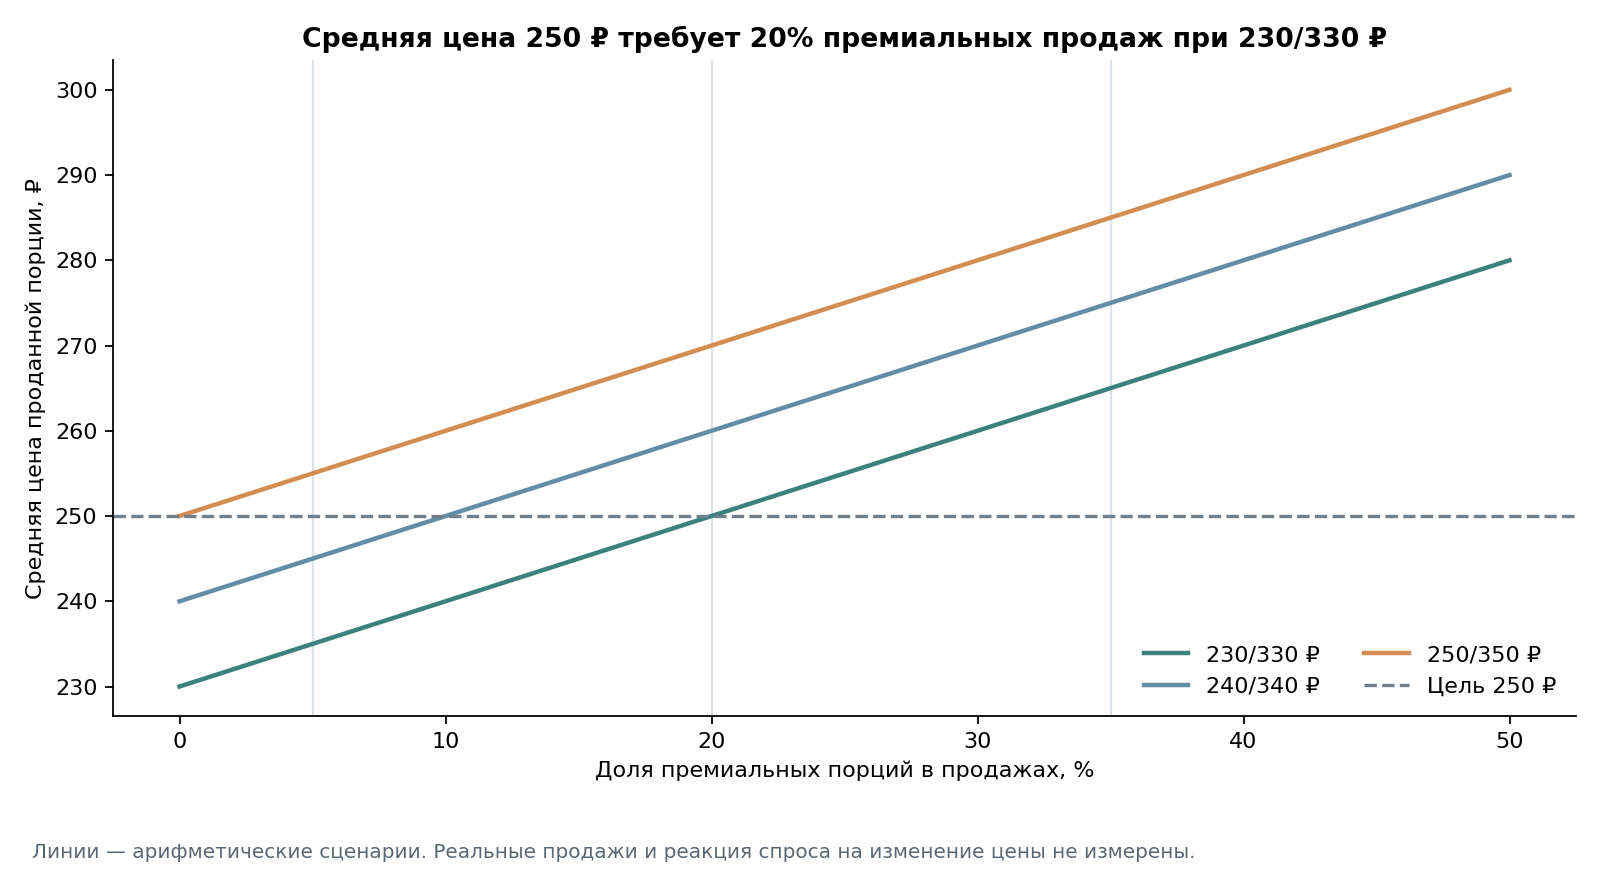

,menu,stress,mix_scenario,premium_share,weighted_price_rub,weighted_cost_50ml_rub,material_margin_50ml_rub,material_margin_fraction,positions_below_margin_threshold
13,B,base,base,0.2,250.0,71.399626,178.600374,0.714401,0
16,B,loss_plus_10pp,base,0.2,250.0,80.439753,169.560247,0.678241,2
19,B,price_plus_10,base,0.2,250.0,78.539589,171.460411,0.685842,2
22,B,price_plus_20,base,0.2,250.0,85.679551,164.320449,0.657282,3
25,B2,base,base,0.2,250.0,69.998530,180.001470,0.720006,0
28,B2,loss_plus_10pp,base,0.2,250.0,78.857742,171.142258,0.684569,2
31,B2,price_plus_10,base,0.2,250.0,76.998383,173.001617,0.692006,2
34,B2,price_plus_20,base,0.2,250.0,83.998236,166.001764,0.664007,2


In [23]:
display(scenarios.loc[scenarios.menu.isin(["B","B2"]) & scenarios.price_pair.eq(0), ["menu","scenario","premium_share","simple_menu_price_rub","weighted_price_rub","weighted_material_cost_50ml_rub","material_margin_50ml_rub","material_margin_fraction","sales_status"]])
display(Image(filename=str(ROOT / "figures/economics/price_mix.png")))
stress = read("stress_menu_scenarios.csv")
display(stress.loc[stress.menu.isin(["B","B2"]) & stress.mix_scenario.eq("base")])

## 9. Предложение для проверки и ограничения

При готовности вложить дополнительные 874 ₽ на старт **B2 предпочтительно проверить первым**: четыре классические и шесть необычных позиций, среди них три именованных сочетания, ноль сильных флагов. Материальная маржа выше примерно на 1,14–1,66 ₽ на сценарную порцию; небольшой эффект может измениться после измерения выхода. Строгая база — 28 событий против 30 у B, совместимость 22,59% против 60,44%. При приоритете кассы и переработки открытого сырья **B сохраняет преимущество**.

Следующие проверки: измерить выход/потери/крепость, сладость и кислотность, сравнить различимость базиликовых вариантов, подтвердить составы и устойчивость молочных позиций, региональные цены/минимумы/наличие, реальные продажи и списания. Ни сроки безопасного хранения, ни коммерческая прибыльность не установлены. Повышение цены не означает автоматического роста выручки.

Мнения авторов отзывов не представляют всех гостей; базы малы, исторические и текущие свидетельства различаются, часть видна фрагментарно. Коммерческие рецепты конкурентов неизвестны. Меню не утверждено. Работа обновляет Draft PR №1 без слияния в main.

In [24]:
assert e.check_baseline()
old = json.loads((ROOT / "data/economics/stage1_baseline.json").read_text())
for name in ["A","B","C"]:
    assert list(result["menus"][name]["selected"]) == old["menus"][name]["selected"]
for name, group in items.groupby("menu"):
    assert len(group) == 10 and group.candidate_id.is_unique
    assert group.tier.eq("basic").sum() == 8 and group.tier.eq("premium").sum() == 2
assert len(candidates) == 15 and len(price_audit) == 21
assert result["menus"]["B2"]["strong_overlap_pairs"] == 0
assert result["menus"]["B2"]["moderate_overlap_pairs"] == 1
print("Исходная база побайтно сохранена. A/B/C сохранены по составу. Все четыре меню: 10 позиций, 8+2.")

Исходная база побайтно сохранена. A/B/C сохранены по составу. Все четыре меню: 10 позиций, 8+2.
